# 27. Stable Matrices and Inertia
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

A Lyapunov function for a stable non-normal system $x'=Ax$ (eigenvalues $-0.3\pm1.5i$, strong shear). Left: Euclidean circles; trajectories (blue) leave some circles outward before eventually spiralling in, so $\lVert x\rVert$ is not monotone. Right: level sets of $V(x)=x^{\mathsf T}Xx$, with $X$ solving $A^{\mathsf T}X+XA=-I$; every trajectory crosses every ellipse inwards, and $V$ decreases strictly.

Text(0.5, 1.0, '$x^{T}Xx$ = const')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


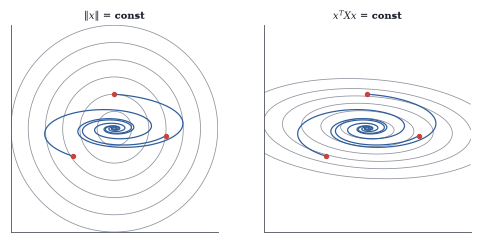

In [2]:
from scipy.linalg import solve_continuous_lyapunov, expm
Al = np.array([[-0.3, 4.0], [-0.56, -0.3]]); Xl = solve_continuous_lyapunov(Al.T, -np.eye(2))
g = np.linspace(-3, 3, 200); GX, GY = np.meshgrid(g, g); Vl = Xl[0, 0] * GX**2 + 2 * Xl[0, 1] * GX * GY + Xl[1, 1] * GY**2
ts = np.linspace(0, 12, 600); starts = [np.array([0.0, 1.0]), np.array([-1.2, -0.8]), np.array([1.5, -0.2])]
fig, axs = plt.subplots(1, 2, figsize=(W, 2.1))
for ax, lv in zip(axs, ["circle", "lyap"]):
    if lv == "circle": ax.contour(GX, GY, np.sqrt(GX**2 + GY**2), levels=np.arange(0.5, 3.1, 0.5), colors=GRAY, linewidths=0.5)
    else: ax.contour(GX, GY, Vl, levels=np.quantile(Vl, [0.02, 0.06, 0.12, 0.2, 0.3, 0.42]), colors=GRAY, linewidths=0.5)
    for x0 in starts:
        tr = np.array([expm(t * Al) @ x0 for t in ts]); ax.plot(tr[:, 0], tr[:, 1], color=BLUE, lw=0.8); ax.plot(*x0, "o", color=RED, ms=2.5)
    ax.set_aspect("equal"); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_xticks([]); ax.set_yticks([])
axs[0].set_title(r"$\|x\|$ = const", fontsize=6.5); axs[1].set_title(r"$x^{T}Xx$ = const", fontsize=6.5)

Routh–Hurwitz for cubics $z^3+a_1z^2+a_2z+a_3$ with $a_3=1$. Each point $(a_1,a_2)$ is coloured by whether all roots have negative real parts (blue) or not (light), computed from the roots. The boundary is exactly the hyperbola $a_1a_2=a_3$ (red) predicted by the criterion $a_1>0$, $a_1a_2>a_3$, $a_3>0$; on it a pair of roots sits on the imaginary axis.

Text(2.5, 2.8, 'stable')

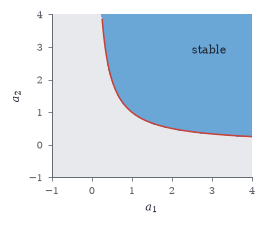

In [3]:
a1s = np.linspace(-1, 4, 220); a2s = np.linspace(-1, 4, 220); stab = np.zeros((len(a2s), len(a1s)))
for i, a2 in enumerate(a2s):
    for j, a1 in enumerate(a1s): stab[i, j] = np.all(np.roots([1, a1, a2, 1.0]).real < 0)
fig, ax = plt.subplots(figsize=(W * 0.5, W * 0.42))
ax.contourf(a1s, a2s, stab, levels=[-0.5, 0.5, 1.5], colors=[LIGHT, SKY]); xx = np.linspace(0.26, 4, 100); ax.plot(xx, 1 / xx, color=RED, lw=1)
ax.set_xlabel("$a_1$"); ax.set_ylabel("$a_2$"); ax.set_xlim(-1, 4); ax.set_ylim(-1, 4); ax.text(2.5, 2.8, "stable", fontsize=7, color=INK)

May's stability bound. Left: eigenvalues of $M=-I+\sigma G$ for $n=400$ species with connectance $C=0.2$ and $\sigma\sqrt{nC}=0.8$ (blue, stable) and $1.2$ (red, unstable); they fill discs centred at $-1$ of radius $\sigma\sqrt{nC}$ (circles). Right: the fraction of random systems that are stable, as a function of $\sigma\sqrt{nC}$, for $n=25,100,400$; the transition sharpens at $1$ as $n$ grows.

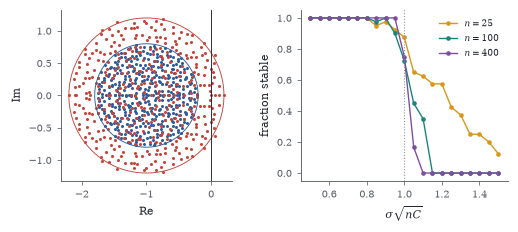

In [4]:
rng = np.random.default_rng(3); C = 0.2
def community(n, s):
    G = rng.normal(size=(n, n)) * (rng.random((n, n)) < C); np.fill_diagonal(G, 0); return -np.eye(n) + s / np.sqrt(n * C) * G
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0))
for s, col in [(0.8, BLUE), (1.2, RED)]:
    ev = np.linalg.eigvals(community(400, s)); axs[0].scatter(ev.real, ev.imag, s=1, color=col); tt = np.linspace(0, 2 * np.pi, 200)
    axs[0].plot(-1 + s * np.cos(tt), s * np.sin(tt), color=col, lw=0.6)
axs[0].axvline(0, color=INK, lw=0.6); axs[0].set_aspect("equal"); axs[0].set_xlabel("Re"); axs[0].set_ylabel("Im")
grid = np.linspace(0.5, 1.5, 21)
for n, col in [(25, GOLD), (100, TEAL), (400, PLUM)]:
    trials = 40 if n < 400 else 12
    frac = [np.mean([np.linalg.eigvals(community(n, s)).real.max() < 0 for _ in range(trials)]) for s in grid]
    axs[1].plot(grid, frac, "o-", color=col, ms=2, lw=0.9, label=f"$n={n}$")
axs[1].axvline(1, color=GRAY, ls=":", lw=0.7); axs[1].set_xlabel(r"$\sigma\sqrt{nC}$"); axs[1].set_ylabel("fraction stable"); axs[1].legend(fontsize=6)

Hankel singular values of a random stable single-input single-output system with $n=40$ states (computed from the two Gramians) decay fast, so a few balanced states carry almost all of the input–output behaviour. Right: the frequency response $|C(i\omega I-A)^{-1}B|$ of the full model (black) and of balanced truncations to $r=2$ and $r=4$ states; with four states the reduced model is indistinguishable from the full one. (Only the first $15$ Hankel singular values are shown; the rest are below $10^{-6}$.)

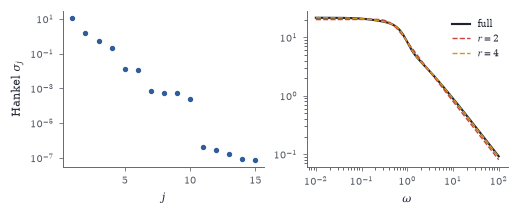

In [5]:
rng = np.random.default_rng(7); n = 40; Ar = rng.normal(size=(n, n)) / np.sqrt(n) * 1.5; Ar -= (np.linalg.eigvals(Ar).real.max() + 0.2) * np.eye(n)
Br = rng.normal(size=(n, 1)); Cr = rng.normal(size=(1, n))
Wc = solve_continuous_lyapunov(Ar, -Br @ Br.T); Wo = solve_continuous_lyapunov(Ar.T, -Cr.T @ Cr)
hsv = np.sqrt(np.abs(np.sort(np.linalg.eigvals(Wc @ Wo).real)[::-1]))
Lc = np.linalg.cholesky(Wc + 1e-12 * np.eye(n)); Lo = np.linalg.cholesky(Wo + 1e-12 * np.eye(n)); Ub, sb, Vbt = np.linalg.svd(Lo.T @ Lc)
def truncate(r):
    S = np.diag(sb[:r] ** -0.5); T = Lc @ Vbt[:r].T @ S; Ti = S @ Ub[:, :r].T @ Lo.T; return Ti @ Ar @ T, Ti @ Br, Cr @ T
ws = np.logspace(-2, 2, 300); resp = lambda A_, B_, C_: [abs((C_ @ np.linalg.solve(1j * w * np.eye(len(A_)) - A_, B_))[0, 0]) for w in ws]
fig, axs = plt.subplots(1, 2, figsize=(W, 1.85))
axs[0].semilogy(np.arange(1, 16), hsv[:15], "o", color=BLUE, ms=2.5); axs[0].set_xlabel("$j$"); axs[0].set_ylabel(r"Hankel $\sigma_j$")
axs[1].loglog(ws, resp(Ar, Br, Cr), color=INK, lw=1.4, label="full")
for r, col in [(2, RED), (4, GOLD)]: axs[1].loglog(ws, resp(*truncate(r)), "--", color=col, lw=0.9, label=f"$r={r}$")
axs[1].set_xlabel(r"$\omega$"); axs[1].legend(fontsize=6)

In [6]:
from scipy.linalg import solve_discrete_lyapunov
rng = np.random.default_rng(1); A5 = rng.normal(size=(5, 5)); A5 *= 0.9 / max(abs(np.linalg.eigvals(A5)))
Xs = sum(np.linalg.matrix_power(A5.T, k) @ np.linalg.matrix_power(A5, k) for k in range(2000)); Xd = solve_discrete_lyapunov(A5.T, np.eye(5))
print("series vs solver agree:", np.allclose(Xs, Xd), "  ||X|| =", round(np.linalg.norm(Xd, 2), 3))
Rx = np.linalg.cholesky(Xd).T; rate = np.sqrt(1 - 1 / np.linalg.norm(Xd, 2))
for k in (1, 5, 20, 50):
    Ak = np.linalg.matrix_power(A5, k); print(f"k={k:2d}  ||A^k||_X = {np.linalg.norm(Rx @ Ak @ np.linalg.inv(Rx), 2):.4f}  <= bound {rate**k:.4f}   (Euclidean ||A^k|| = {np.linalg.norm(Ak, 2):.4f})")

series vs solver agree: True   ||X|| = 20.861
k= 1  ||A^k||_X = 0.9757  <= bound 0.9757   (Euclidean ||A^k|| = 1.4551)
k= 5  ||A^k||_X = 0.7276  <= bound 0.8844   (Euclidean ||A^k|| = 1.5972)
k=20  ||A^k||_X = 0.1425  <= bound 0.6119   (Euclidean ||A^k|| = 0.2755)
k=50  ||A^k||_X = 0.0063  <= bound 0.2929   (Euclidean ||A^k|| = 0.0132)


In [7]:
rng = np.random.default_rng(0); Ai = np.diag([2.0, -1, -3]) + np.triu(rng.normal(size=(3, 3)) * 3, 1)
Xi = solve_continuous_lyapunov(Ai.T, np.eye(3)); print("eigenvalues of X:", np.round(np.linalg.eigvalsh(Xi), 4))

eigenvalues of X: [-0.6618 -0.2666  0.7922]
